# Figure S-TSS-sets — TSS features aggregated over pathways and chromosome arms

No_deep cohort, frozen outer folds. The model TSSs grouped into the 50 MSigDB Hallmark pathways and the 39 autosomal chromosome arms; set-level features in two modes:

- averaged: the per-TSS feature (row z-scored as the classifier sees it) averaged over the TSSs of a set;
- pooled: the feature computed once on the set as a whole (summed coverage profile for Griffin difference / RCOV / MWH; summed short and long counts for FSLR).

Each (set type, mode, feature) is run fully nested (six classifiers tuned in a 3-fold inner CV, classifier chosen per outer fold). Points: fold-mean AUROC ± SD over the ten outer folds; a: BRCA/CRC versus healthy, b: pan-cancer versus healthy. Reference AUROCs (data-driven model, ATAC and RNA comparators) are printed, not drawn.

Source data: `data/no_deep/figS_tss_sets_{runs,reference}.csv`, written by `COHORT_VARIANT=no_deep python src/figures/export/export_figS_tss_sets.py`. Run from `src/figures/`.

In [1]:
import os
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT == "no_deep", "the TSS-set analysis exists for the no_deep cohort only"
_DATA, _OUT = os.path.join("data", COHORT), os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

runs = pd.read_csv(os.path.join(_DATA, "figS_tss_sets_runs.csv"))
ref = pd.read_csv(os.path.join(_DATA, "figS_tss_sets_reference.csv"))
FEATURES = ["griffin_diff", "rcov", "mwh", "fslr", "fslr_coverage"]
FLABEL = {"griffin_diff": "Griffin difference", "rcov": "RCOV", "mwh": "MWH", "fslr": "FSLR",
          "fslr_coverage": "FSLR (coverage)"}
ARMS = [("hallmark", "averaged"), ("hallmark", "pooled"), ("arm", "averaged"), ("arm", "pooled")]
COLOR = {"hallmark": "#0173B2", "arm": "#DE8F05"}
MARKER = {"averaged": "o", "pooled": "s"}
SLABEL = {"hallmark": "Hallmark pathways", "arm": "chromosome arms"}
TASK_TITLE = {"brca_crc": "BRCA/CRC vs healthy", "pancan": "pan-cancer vs healthy"}
n_expected = 2 * len(FEATURES) * len(ARMS)
print(f"{len(runs)} of {n_expected} runs available")

40 of 40 runs available


In [2]:
def panel(ax, task):
    d = runs[runs["task"] == task].set_index(["set_type", "mode", "feature"])
    yy = np.arange(len(FEATURES))[::-1]
    offs = np.linspace(-0.27, 0.27, len(ARMS))
    for (st, mode), off in zip(ARMS, offs):
        for f, y in zip(FEATURES, yy):
            if (st, mode, f) not in d.index:
                continue
            r = d.loc[(st, mode, f)]
            ax.errorbar(r["auc_fold_mean"], y + off, xerr=r["auc_fold_sd"], fmt=MARKER[mode], color=COLOR[st],
                        mfc=COLOR[st] if mode == "pooled" else "white", ms=6, capsize=2, lw=1.1)
    ax.axvline(0.5, color="lightgray", lw=0.8)
    ax.set_yticks(yy)
    ax.set_yticklabels([FLABEL[f] for f in FEATURES], fontsize=10)
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("AUROC (fold mean +/- SD, fully nested)", fontsize=10.5)
    ax.set_title(TASK_TITLE[task], fontsize=11)
    ax.grid(axis="x", alpha=0.3)


def legend_handles():
    return [Line2D([], [], color=COLOR[st], marker=MARKER[mode], mfc=COLOR[st] if mode == "pooled" else "white",
                   ls="none", ms=6, label=f"{SLABEL[st]}, {mode}") for st, mode in ARMS]

## Assembled figure

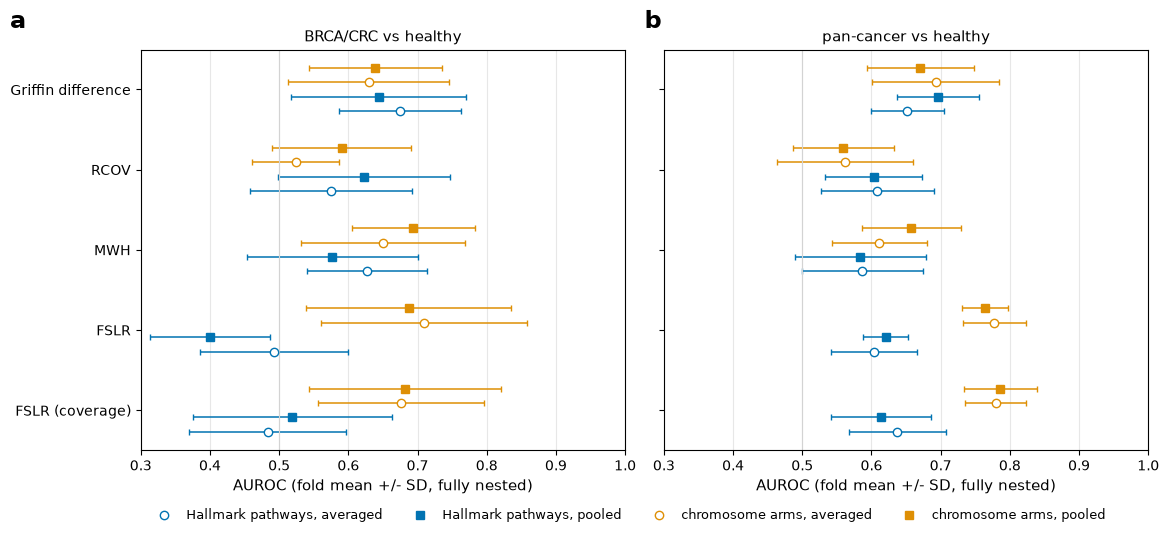

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, gridspec_kw={"wspace": 0.08})
panel(axes[0], "brca_crc"); panel(axes[1], "pancan")
for ax, letter in zip(axes, "ab"):
    ax.text(-0.04 if letter == "b" else -0.27, 1.04, letter, transform=ax.transAxes, fontsize=17,
            fontweight="bold", va="bottom")
fig.legend(handles=legend_handles(), loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.savefig(os.path.join(_OUT, "figS_tss_sets.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(_OUT, "figS_tss_sets.pdf"), bbox_inches="tight")
plt.show()

## Summary numbers

In [4]:
pd.set_option("display.width", 200)
print(ref.round(3).to_string(index=False))
print()
for task in ["brca_crc", "pancan"]:
    d = runs[runs["task"] == task]
    print(f"{task}: best per set type / mode")
    print(d.loc[d.groupby(["set_type", "mode"])["auc_fold_mean"].idxmax(),
                ["set_type", "mode", "feature", "n_sets", "auc_fold_mean", "auc_fold_sd", "classifiers"]].round(3).to_string(index=False))
    print()
# the range over all 20 arms, and the comparison of the two aggregation modes (same set type, task and feature)
for task in ["brca_crc", "pancan"]:
    d = runs[runs["task"] == task]
    w = d.pivot_table(index=["set_type", "feature"], columns="mode", values="auc_fold_mean")
    print(f"{task}: all arms {d['auc_fold_mean'].min():.3f}-{d['auc_fold_mean'].max():.3f}; pooled higher than averaged in {int((w['pooled'] > w['averaged']).sum())} of {len(w)}; "
          f"median pooled - averaged {(w['pooled'] - w['averaged']).median():+.3f}")
    for st in ["hallmark", "arm"]:
        x = d[d["set_type"] == st]
        print(f"   {st}: {x['auc_fold_mean'].min():.3f}-{x['auc_fold_mean'].max():.3f}; best per feature " +
              ", ".join(f"{f} {x[x['feature'] == f]['auc_fold_mean'].max():.3f}" for f in FEATURES))


    task      method  auc_fold_mean  auc_fold_sd  auc_pooled_oof
brca_crc data_driven          0.966        0.029           0.960
brca_crc        atac          0.891        0.096           0.892
brca_crc         rna          0.666        0.108           0.613
  pancan data_driven          0.969        0.015           0.967
  pancan        atac          0.897        0.057           0.884
  pancan         rna          0.676        0.069           0.652

brca_crc: best per set type / mode
set_type     mode      feature  n_sets  auc_fold_mean  auc_fold_sd                                                                                    classifiers
     arm averaged         fslr      39          0.709        0.149                            Support Vector Machine x6, Random Forest x3, Logistic Regression x1
     arm   pooled          mwh      39          0.694        0.089       Support Vector Machine x7, Multi-Layer Perceptron x1, XGBoost x1, Logistic Regression x1
hallmark averaged griff